# Phase B.2 - Decoder Fine-Tuning Experiment
Objective:

Evaluate whether adapting a small subset of decoder parameters improves agricultural parcel segmentation under the SA‑1B → Sentinel‑2 domain shift.

Trainable parameters:

* transformer.layers[1]
* iou_prediction_head

Total trainable:

* 1,712,132 parameters

* 3.72 % of the model

In [6]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.optim as optim

from PIL import Image

from google.colab import drive

# URL de repositorio
!git clone https://github.com/ZagonTM/Sen4Sam
# Una vez clonado, nos movemos al directorio del repositorio o lo añadimos al path
import os
if os.path.exists('Sen4Sam'):
    %cd Sen4Sam
    print("Acceso al repositorio Sen4Sam exitoso.")
else:
    print("No se pudo encontrar la carpeta del repositorio. Verifica la URL de clonación.")

# Instalar Segment Anything 2 (SAM 2) y sus dependencias
!pip install -q git+https://github.com/facebookresearch/sam2.git

# Crear directorio de checkpoints y descargar los pesos del modelo
!mkdir -p checkpoints
!wget -P checkpoints/ https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_small.pt

ROOT = Path.cwd()

DATA_ROOT = Path(
    "/content/drive/MyDrive/Sen4SAM"
)

PROCESSED = (
    DATA_ROOT /
    "processed"
)

Cloning into 'Sen4Sam'...
remote: Enumerating objects: 200, done.
remote: Counting objects: 100% (200/200), done.
remote: Compressing objects: 100% (143/143), done.
remote: Total 200 (delta 95), reused 141 (delta 54), pack-reused 0 (from 0)
Receiving objects: 100% (200/200), 3.92 MiB | 8.61 MiB/s, done.
Resolving deltas: 100% (95/95), done.
/content/Sen4Sam
Acceso al repositorio Sen4Sam exitoso.
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
--2026-11-09 02:09:24--  https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_small.pt
Resolving dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)... 54.192.138.13, 54.192.138.127, 

In [7]:
# Comprobar que Colab usa GPU (sin GPU el encoder tarda ~8 s por imagen en lugar de ~0.3 s).
# Si falla: Entorno de ejecucion > Cambiar tipo de entorno de ejecucion > T4 GPU, y volver a ejecutar desde el principio.
import torch

REQUIRE_GPU = True

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
elif REQUIRE_GPU:
    raise RuntimeError("No hay GPU activa. Activa una GPU en el tipo de entorno de ejecucion de Colab.")
else:
    print("AVISO: ejecutando sin GPU (muy lento).")

GPU: Tesla T4


Configuracion

In [8]:
EPOCHS = 100          # maximo; el early stopping corta antes si hay sobreajuste

LR = 1e-4

# Datos de entrenamiento: parcelas tomadas de parches "train" (None = todos)
N_TRAIN_PATCHES = 200         # de 624 parches de train; 624 = todos (mas memoria GPU y mas tiempo)
TRAIN_PARCELS_PER_PATCH = 30  # parcelas por parche; None = todas las parcelas del parche
TRAIN_SAMPLES = None          # tope opcional del total de parcelas (None = sin tope)

# Peso de la perdida del IoU head respecto al Dice (ambas ~0.1-1)
IOU_LOSS_WEIGHT = 1.0
# Early stopping sobre la perdida de validacion
PATIENCE = 5          # epocas seguidas sin mejora
MIN_DELTA = 1e-3      # mejora minima para contar como mejora

# Validacion: parcelas de parches "val" (no de test)
N_VAL_PATCHES = 30
VAL_PARCELS_PER_PATCH = 50

LOG_EVERY = 500       # imprimir progreso cada N parcelas


Dataset

In [9]:
def load_rgb(patch):

    return np.array(
        Image.open(
            DATA_ROOT / "processed" / f"{patch}_rgb.png"
        ).convert("RGB")
    )
def load_parcels(patch):

    return np.load(
        DATA_ROOT / "processed" / f"{patch}_parcels.npy"
    )

from google.colab import drive

drive.mount('/content/drive')

# Los datos NO se descargan: tienen que estar en tu Drive (carpeta Sen4SAM con processed/processed/)
assert (DATA_ROOT / "processed").exists(), (
    "No se encuentra Drive/Sen4SAM/processed/processed/ (parches procesados). "
    "Copia la carpeta compartida a tu MyDrive o descomprime processed.zip (ver notebook 03)."
)

# Split train/val/test por PARCHE (results/split.csv, semilla 42, estratificado por tesela).
# Para entrenar solo se usan parches de "train"; "test" queda reservado para la evaluacion final.
SPLIT_PATH = next((p for p in [ROOT / "results" / "split.csv", DATA_ROOT / "split.csv"] if p.exists()), None)
assert SPLIT_PATH is not None, "No se encuentra split.csv (repositorio: results/split.csv, o Drive: Sen4SAM/split.csv)"
split = pd.read_csv(SPLIT_PATH)


# Tabla de parcelas (centroide como prompt, area >= 20 px, igual que en el notebook 05a).
# Se construye aqui a partir de los mapas de parcelas, por lo que no hace falta gt_parcel_dataset.csv.
# per_patch=None usa todas las parcelas del parche.
def build_parcel_table(patches, per_patch, seed):
    rng = np.random.RandomState(seed)
    rows = []
    for patch in patches:
        parcel_map = load_parcels(patch)
        ids = [i for i in np.unique(parcel_map) if i != 0 and (parcel_map == i).sum() >= 20]
        if not ids:
            continue
        size = len(ids) if per_patch is None else min(per_patch, len(ids))
        for pid in rng.choice(ids, size=size, replace=False):
            ys, xs = np.where(parcel_map == pid)
            rows.append({"patch": patch, "parcel_id": int(pid), "area": int(len(xs)),
                         "cx": float(xs.mean()), "cy": float(ys.mean())})
    return pd.DataFrame(rows)


# Entrenamiento: parches de "train"
train_pool = split.loc[split["split"] == "train", "patch"].tolist()
n_patches = len(train_pool) if N_TRAIN_PATCHES is None else min(N_TRAIN_PATCHES, len(train_pool))
train_patches = list(np.random.RandomState(42).choice(train_pool, size=n_patches, replace=False))
train_df = build_parcel_table(train_patches, TRAIN_PARCELS_PER_PATCH, 42)
if TRAIN_SAMPLES is not None:
    train_df = train_df.sample(min(TRAIN_SAMPLES, len(train_df)), random_state=42)
print("split:", SPLIT_PATH, "| entrenamiento:", len(train_df), "parcelas de",
      train_df["patch"].nunique(), "parches (de", len(train_pool), "parches de train)")

# Validacion: parches "val"
val_pool = split.loc[split["split"] == "val", "patch"].tolist()
val_patches = list(np.random.RandomState(42).choice(
    val_pool, size=min(N_VAL_PATCHES, len(val_pool)), replace=False))
val_df = build_parcel_table(val_patches, VAL_PARCELS_PER_PATCH, 42)
print("validacion:", len(val_df), "parcelas de", len(val_patches), "parches")


Mounted at /content/drive
split: /content/Sen4Sam/results/split.csv | entrenamiento: 5544 parcelas de 200 parches (de 624 parches de train)
validacion: 1394 parcelas de 30 parches


Optimizador

In [10]:
sys.path.insert(
    0,
    str(ROOT / "src")
)
from sam2_auto_segment import build_model

model = build_model()

# Congelar todo
for p in model.parameters():
    p.requires_grad = False

# Seleccionar componentes de la intervención
last_block = (
    model.sam_mask_decoder
    .transformer
    .layers[1]
)

iou_head = (
    model.sam_mask_decoder
    .iou_prediction_head
)

# Descongelar únicamente estas capas
for p in last_block.parameters():
    p.requires_grad = True

for p in iou_head.parameters():
    p.requires_grad = True

# Verificamos
trainable = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Trainable:", trainable)

#Predictor
from sam2.sam2_image_predictor import SAM2ImagePredictor
predictor = SAM2ImagePredictor(model)

#Optimizador
optimizer = torch.optim.Adam(
    filter(
        lambda p: p.requires_grad,
        model.parameters()
    ),
    lr=LR
)

Trainable: 1712132


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## Baseline: modelo sin entrenar sobre el conjunto de TEST

Antes de entrenar se evalua el modelo original con el generador automatico de mascaras
sobre los parches de **test** (`results/split.csv`). Mismos ajustes y mismas metricas que la
linea base de `src/evaluate_masks.py` (`points_per_side=16`, `pred_iou_thresh=0.5`,
`stability_score_thresh=0.8`). Despues del entrenamiento se repite esta evaluacion para comparar.


In [11]:
import time
from evaluate_masks import evaluate_patch
from sam2_auto_segment import build_mask_generator

EVAL_LIMIT = None   # p.ej. 10 para una prueba rapida; None = todos los parches de test

test_patches = split.loc[split["split"] == "test", ["country", "tile", "patch"]]
if EVAL_LIMIT:
    test_patches = test_patches.head(EVAL_LIMIT)


def evaluate_model_on_patches(model, patches_df):
    generator = build_mask_generator(
        model, points_per_side=16, pred_iou_thresh=0.5, stability_score_thresh=0.8
    )
    rows = []
    t0 = time.time()
    for i, r in enumerate(patches_df.itertuples(index=False), 1):
        metrics = evaluate_patch(load_rgb(r.patch), load_parcels(r.patch), generator)
        rows.append({"country": r.country, "tile": r.tile, "patch": r.patch, **metrics})
        if i % 20 == 0 or i == len(patches_df):
            print(f"[{i}/{len(patches_df)}] {time.time() - t0:.0f}s")
    return pd.DataFrame(rows)


SUMMARY_COLS = ["mean_best_iou", "median_best_iou", "frac_iou_gt_0.5", "mask_on_field_fraction", "n_masks"]


def summarize_eval(df, title):
    print(f"\n=== {title} ({len(df)} parches) ===")
    print(df[SUMMARY_COLS].mean().round(4).to_string())
    print()
    print(df.groupby("country")[SUMMARY_COLS].mean().round(4).to_string())


baseline_test = evaluate_model_on_patches(model, test_patches)
baseline_test.to_csv(DATA_ROOT / "eval_test_untrained.csv", index=False)
summarize_eval(baseline_test, "Modelo sin entrenar - TEST")

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


[20/132] 48s
[40/132] 95s
[60/132] 145s
[80/132] 195s
[100/132] 245s
[120/132] 297s
[132/132] 327s

=== Modelo sin entrenar - TEST (132 parches) ===
mean_best_iou              0.1560
median_best_iou            0.0434
frac_iou_gt_0.5            0.1423
mask_on_field_fraction     0.5829
n_masks                   78.7197

         mean_best_iou  median_best_iou  frac_iou_gt_0.5  mask_on_field_fraction   n_masks
country                                                                                   
ES              0.0755           0.0040           0.0600                  0.4279   41.4848
FR              0.2365           0.0828           0.2246                  0.7380  115.9545


In [12]:
# Control: los mismos parches ya estan en results/eval_patches.csv (linea base de los 888 parches).
# Las diferencias deben ser ~0 (solo ruido numerico del dispositivo).
ref_path = ROOT / "results" / "eval_patches.csv"
if ref_path.exists():
    ref = pd.read_csv(ref_path).set_index("patch").loc[baseline_test["patch"]]
    diff = (baseline_test.set_index("patch")["mean_best_iou"] - ref["mean_best_iou"]).abs()
    print("mean_best_iou aqui     :", round(baseline_test["mean_best_iou"].mean(), 4))
    print("mean_best_iou en el CSV:", round(ref["mean_best_iou"].mean(), 4))
    print("diferencia absoluta max por parche:", round(diff.max(), 4))
else:
    print("results/eval_patches.csv no encontrado; se omite el control.")

mean_best_iou aqui     : 0.156
mean_best_iou en el CSV: 0.156
diferencia absoluta max por parche: 0.0


Bucle de entrenamiento

In [13]:
print("TRAIN_SAMPLES =", TRAIN_SAMPLES)

print("Filas de train_df =", len(train_df))

print("Filas de val_df =", len(val_df))

TRAIN_SAMPLES = None
Filas de train_df = 5544
Filas de val_df = 1394


### Validacion y early stopping

La perdida de validacion (parches `val`, nunca usados para entrenar) se calcula al final de cada epoca. Si no mejora `MIN_DELTA` durante `PATIENCE` epocas seguidas, el entrenamiento se detiene y se restauran los pesos de la mejor epoca.


In [12]:
import torch.nn.functional as F

# Validacion (parches "val"): misma perdida que en entrenamiento, sin gradientes.
val_cache = {}


def evaluate_validation():
    image_pe = model.sam_prompt_encoder.get_dense_pe()
    sums = {"loss": 0.0, "dice": 0.0, "iou": 0.0, "mask_iou": 0.0}

    with torch.no_grad():
        for _, row in val_df.iterrows():
            patch = row["patch"]

            if patch not in val_cache:
                predictor.set_image(load_rgb(patch))
                val_cache[patch] = {
                    "image_embed": predictor._features["image_embed"],
                    "high_res_feats": predictor._features["high_res_feats"],
                    "parcels": load_parcels(patch),
                }

            image_embed = val_cache[patch]["image_embed"]

            point_coords = predictor._transforms.transform_coords(
                torch.tensor([[[row["cx"], row["cy"]]]], dtype=torch.float32,
                             device=image_embed.device),
                normalize=True,
                orig_hw=(366, 366)
            )
            point_labels = torch.tensor([[1]], dtype=torch.int64, device=image_embed.device)

            sparse_embeddings, dense_embeddings = model.sam_prompt_encoder(
                points=(point_coords, point_labels), boxes=None, masks=None
            )
            masks, iou_pred, _, _ = model.sam_mask_decoder.predict_masks(
                image_embeddings=image_embed,
                image_pe=image_pe,
                sparse_prompt_embeddings=sparse_embeddings,
                dense_prompt_embeddings=dense_embeddings,
                repeat_image=False,
                high_res_features=val_cache[patch]["high_res_feats"],
            )

            gt = torch.tensor((val_cache[patch]["parcels"] == row["parcel_id"]).astype(np.float32),
                              device=image_embed.device)[None, None]
            gt = F.interpolate(gt, size=masks.shape[-2:], mode="nearest")

            dice = dice_loss(torch.sigmoid(masks[:, 0:1]), gt)

            pred_bin = (masks > 0).float()
            inter = (pred_bin * gt).sum(dim=(-2, -1))
            union = pred_bin.sum(dim=(-2, -1)) + gt.sum(dim=(-2, -1)) - inter
            true_iou = inter / union.clamp(min=1.0)
            iou_loss = F.mse_loss(iou_pred, true_iou)

            sums["loss"] += (dice + IOU_LOSS_WEIGHT * iou_loss).item()
            sums["dice"] += dice.item()
            sums["iou"] += iou_loss.item()
            sums["mask_iou"] += true_iou[0, 0].item()   # "accuracy": IoU de la mascara (token 0)

    return {k: v / len(val_df) for k, v in sums.items()}


# Pesos entrenables: guardar / restaurar (para volver a la mejor epoca)
trainable_params = [(n, p) for n, p in model.named_parameters() if p.requires_grad]


def get_trainable_state():
    return {n: p.detach().cpu().clone() for n, p in trainable_params}


def set_trainable_state(state):
    with torch.no_grad():
        for n, p in trainable_params:
            p.copy_(state[n].to(p.device))


In [16]:

import torch.nn.functional as F

PROCESSED = (
    DATA_ROOT /
    "processed"
)

def load_parcel_mask(
    patch,
    parcel_id
):

    parcels = np.load(
        PROCESSED /
        f"{patch}_parcels.npy"
    )

    return (
        parcels == parcel_id
    ).astype(np.float32)

def dice_loss(
    pred,
    target,
    eps=1e-6
):

    pred = pred.reshape(-1)

    target = target.reshape(-1)

    inter = (
        pred * target
    ).sum()

    dice = (
        2 * inter + eps
    ) / (
        pred.sum()
        + target.sum()
        + eps
    )

    return 1 - dice

import time

feature_cache = {}

epoch_losses = []

# Epoca 0: modelo sin entrenar (solo validacion); punto de partida del early stopping
history = []
val0 = evaluate_validation()
history.append({"epoch": 0, "val_loss": val0["loss"], "val_dice": val0["dice"],
                "val_iou_loss": val0["iou"], "val_mask_iou": val0["mask_iou"]})
print(f"Epoca 0 (sin entrenar): val_loss={val0['loss']:.4f} val_mask_iou={val0['mask_iou']:.4f}")

best_val = val0["loss"]
best_epoch = 0
best_state = get_trainable_state()
epochs_without_improvement = 0
stopped_early = False

for epoch in range(EPOCHS):

    running_loss = 0
    running_dice = 0
    running_iou = 0
    running_miou = 0

    print(
        f"\n========== Epoch {epoch+1}/{EPOCHS} =========="
    )

    for local_idx, (_, row) in enumerate(
        train_df.iterrows()
    ):

        patch = row["patch"]

        # -----------------------------------
        # CACHE DEL ENCODER
        # -----------------------------------

        if patch not in feature_cache:

            image = load_rgb(patch)

            start_encoder = time.time()

            predictor.set_image(image)

            encoder_time = (
                time.time()
                - start_encoder
            )

            print(
                f"[ENCODER] {patch} "
                f"{encoder_time:.2f}s"
            )

            feature_cache[patch] = {

                "image_embed":
                    predictor._features[
                        "image_embed"
                    ],

                "high_res_feats":
                    predictor._features[
                        "high_res_feats"
                    ]
            }

        image_embed = (
            feature_cache[patch]
            ["image_embed"]
        )

        high_res_feats = (
            feature_cache[patch]
            ["high_res_feats"]
        )

        # -----------------------------------
        # POSITIONAL ENCODING
        # -----------------------------------

        image_pe = (
            model.sam_prompt_encoder
            .get_dense_pe()
        )

        # -----------------------------------
        # PROMPT
        # -----------------------------------

        # Las parcelas estan en pixeles del parche (366x366); SAM espera coordenadas en su marco de 1024x1024.
        # transform_coords normaliza por (alto, ancho) y escala a 1024 (igual que predictor.predict).
        point_coords = predictor._transforms.transform_coords(
            torch.tensor([[[row["cx"], row["cy"]]]], dtype=torch.float32,
                         device=image_embed.device),
            normalize=True,
            orig_hw=(366, 366)
        )

        point_labels = torch.tensor(
            [[1]],
            dtype=torch.int64,
            device=image_embed.device
        )

        sparse_embeddings, dense_embeddings = (
            model.sam_prompt_encoder(
                points=(
                    point_coords,
                    point_labels
                ),
                boxes=None,
                masks=None
            )
        )

        # -----------------------------------
        # DECODER
        # -----------------------------------

        masks, iou_pred, mask_tokens, obj_logits = (
            model.sam_mask_decoder.predict_masks(

                image_embeddings=image_embed,

                image_pe=image_pe,

                sparse_prompt_embeddings=sparse_embeddings,

                dense_prompt_embeddings=dense_embeddings,

                repeat_image=False,

                high_res_features=high_res_feats
            )
        )

        # -----------------------------------
        # GT
        # -----------------------------------

        gt_mask = load_parcel_mask(
            patch,
            row["parcel_id"]
        )

        gt_mask = torch.tensor(
            gt_mask,
            dtype=torch.float32,
            device=image_embed.device
        )

        gt_mask = (
            gt_mask
            .unsqueeze(0)
            .unsqueeze(0)
        )

        gt_mask = F.interpolate(
            gt_mask,
            size=(
                masks.shape[-2],
                masks.shape[-1]
            ),
            mode="nearest"
        )

        # -----------------------------------
        # LOSS
        # -----------------------------------

        # Perdida de mascara: Dice sobre el token 0 (salida unica)
        pred_probs = torch.sigmoid(
            masks[:, 0:1]
        )

        dice = dice_loss(
            pred_probs,
            gt_mask
        )

        # Perdida del IoU head: IoU real (contra la parcela) de cada una de las 4 mascaras
        # que produce el decoder. El generador automatico usa las salidas 1-3, por eso
        # se supervisan las 4 salidas del IoU head (no solo la 0). El IoU real es el objetivo,
        # sin gradiente; el gradiente llega al IoU head y a layers[1].
        with torch.no_grad():
            pred_bin = (masks > 0).float()                                  # (1, 4, H, W)
            inter = (pred_bin * gt_mask).sum(dim=(-2, -1))                  # (1, 4)
            union = (
                pred_bin.sum(dim=(-2, -1))
                + gt_mask.sum(dim=(-2, -1))
                - inter
            )
            true_iou = inter / union.clamp(min=1.0)

        iou_loss = F.mse_loss(
            iou_pred,
            true_iou
        )

        loss = dice + IOU_LOSS_WEIGHT * iou_loss

        optimizer.zero_grad()

        loss.backward()

        # -----------------------------------
        # VERIFICAR GRADIENTES
        # -----------------------------------

        if (
            epoch == 0
            and local_idx == 0
        ):

            grad = next(
                last_block.parameters()
            ).grad

            print(
                "Gradient norm:",
                grad.norm().item()
            )

            iou_grad = next(
                iou_head.parameters()
            ).grad

            print(
                "IoU head gradient norm:",
                iou_grad.norm().item()
            )

        optimizer.step()

        running_loss += loss.item()
        running_dice += dice.item()
        running_iou += iou_loss.item()
        running_miou += true_iou[0, 0].item()

        if (local_idx + 1) % LOG_EVERY == 0:
            print(
                f"[{local_idx+1}/{len(train_df)}] "
                f"Loss={loss.item():.4f} "
                f"(dice={dice.item():.4f}, iou_loss={iou_loss.item():.4f})"
            )

    mean_loss = (
        running_loss
        / len(train_df)
    )

    epoch_losses.append(
        mean_loss
    )

    print(
        f"Epoch {epoch+1} "
        f"Mean Loss = {mean_loss:.4f} "
        f"(dice={running_dice / len(train_df):.4f}, "
        f"iou_loss={running_iou / len(train_df):.4f})"
    )

    # -----------------------------------
    # VALIDACION Y EARLY STOPPING
    # -----------------------------------

    val_stats = evaluate_validation()

    history.append({
        "epoch": epoch + 1,
        "train_loss": mean_loss,
        "train_dice": running_dice / len(train_df),
        "train_iou_loss": running_iou / len(train_df),
        "train_mask_iou": running_miou / len(train_df),
        "val_loss": val_stats["loss"],
        "val_dice": val_stats["dice"],
        "val_iou_loss": val_stats["iou"],
        "val_mask_iou": val_stats["mask_iou"],
    })

    improved = val_stats["loss"] < best_val - MIN_DELTA

    print(
        f"  Validacion: loss={val_stats['loss']:.4f} "
        f"(dice={val_stats['dice']:.4f}, iou_loss={val_stats['iou']:.4f}) "
        f"mask_iou={val_stats['mask_iou']:.4f} {'<- mejor' if improved else ''}"
    )

    if improved:
        best_val = val_stats["loss"]
        best_epoch = epoch + 1
        best_state = get_trainable_state()
        epochs_without_improvement = 0
        torch.save(best_state, DATA_ROOT / "sam2_decoder_best_trainable.pt")
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        stopped_early = True
        print(
            f"\nEarly stopping: {PATIENCE} epocas sin mejora de la perdida de validacion. "
            f"Mejor epoca = {best_epoch}."
        )
        break

# Volver a los pesos de la mejor epoca (menor perdida de validacion)
set_trainable_state(best_state)
torch.save(best_state, DATA_ROOT / "sam2_decoder_best_trainable.pt")
history_df = pd.DataFrame(history)
history_df.to_csv(DATA_ROOT / "training_history.csv", index=False)
print(
    f"\nEpocas ejecutadas: {len(history) - 1} | mejor epoca: {best_epoch} | "
    f"val_loss: {best_val:.4f} | early stopping: {stopped_early}"
)

Epoca 0 (sin entrenar): val_loss=0.8032 val_mask_iou=0.3123

========== Epoch 1/100 ==========
[ENCODER] 2019_31TDK_patch_06_20 0.04s
Gradient norm: 0.06832951307296753
IoU head gradient norm: 0.7052463293075562
[ENCODER] 2019_31TDK_patch_22_17 0.05s
[ENCODER] 2019_31TCL_patch_01_19 0.03s
[ENCODER] 2019_31TCL_patch_00_28 0.03s
[ENCODER] 2019_31TDK_patch_16_14 0.03s
[ENCODER] 2019_31TDK_patch_23_27 0.05s
[ENCODER] 2019_31TCG_patch_17_14 0.06s
[ENCODER] 2019_31TBF_patch_27_10 0.03s
[ENCODER] 2019_31UCP_patch_01_20 0.03s
[ENCODER] 2019_31TCG_patch_11_13 0.03s
[ENCODER] 2019_31TCL_patch_16_03 0.03s
[ENCODER] 2019_31TBF_patch_22_06 0.03s
[ENCODER] 2019_31TBF_patch_25_03 0.03s
[ENCODER] 2019_31TBF_patch_28_13 0.05s
[ENCODER] 2019_31UCP_patch_09_17 0.04s
[ENCODER] 2019_31TBF_patch_27_09 0.03s
[ENCODER] 2019_31TBF_patch_18_26 0.03s
[ENCODER] 2019_31TDG_patch_16_16 0.03s
[ENCODER] 2019_31TDG_patch_24_22 0.03s
[ENCODER] 2019_31TDG_patch_07_13 0.04s
[500/5544] Loss=0.2570 (dice=0.2499, iou_loss=0

Curva entrenamiento

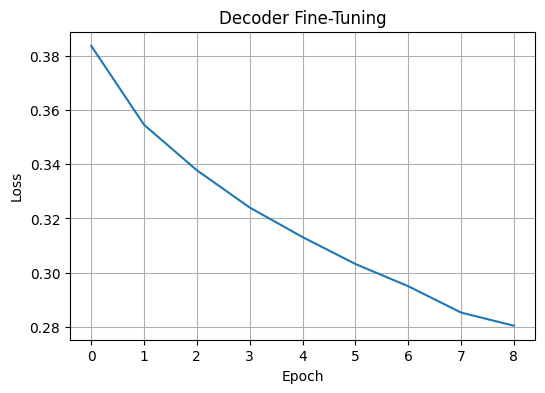

In [18]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6,4))

plt.plot(epoch_losses)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title(
    "Decoder Fine-Tuning"
)

plt.grid(True)

plt.show()

Guardar checkpoint

In [19]:
print([n for n in ("model", "history", "epoch_losses", "best_epoch") if n in globals()])

['model', 'history', 'epoch_losses', 'best_epoch']


NameError: name 'image' is not defined

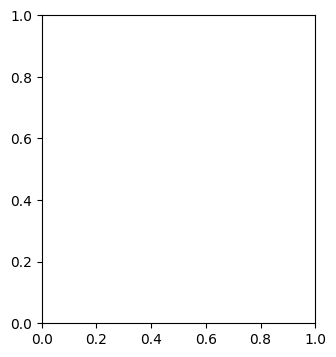

In [20]:
plt.figure(figsize=(12,4))

plt.subplot(131)
plt.imshow(image)
plt.title("RGB")

plt.subplot(132)
plt.imshow(gt_mask[0,0].cpu())
plt.title("Ground Truth")

plt.subplot(133)
plt.imshow(pred_probs[0,0].detach().cpu())
plt.title("Prediction")

plt.show()

In [21]:
torch.save(

    model.state_dict(),

    DATA_ROOT /
    "sam2_decoder_finetuned.pt"
)

## Curvas de entrenamiento y validacion

`mask_iou` es la "accuracy" de segmentacion (IoU de la mascara contra la parcela); la exactitud por pixel no sirve porque domina el fondo. Las metricas de train se promedian durante la epoca; la epoca 0 solo tiene validacion.


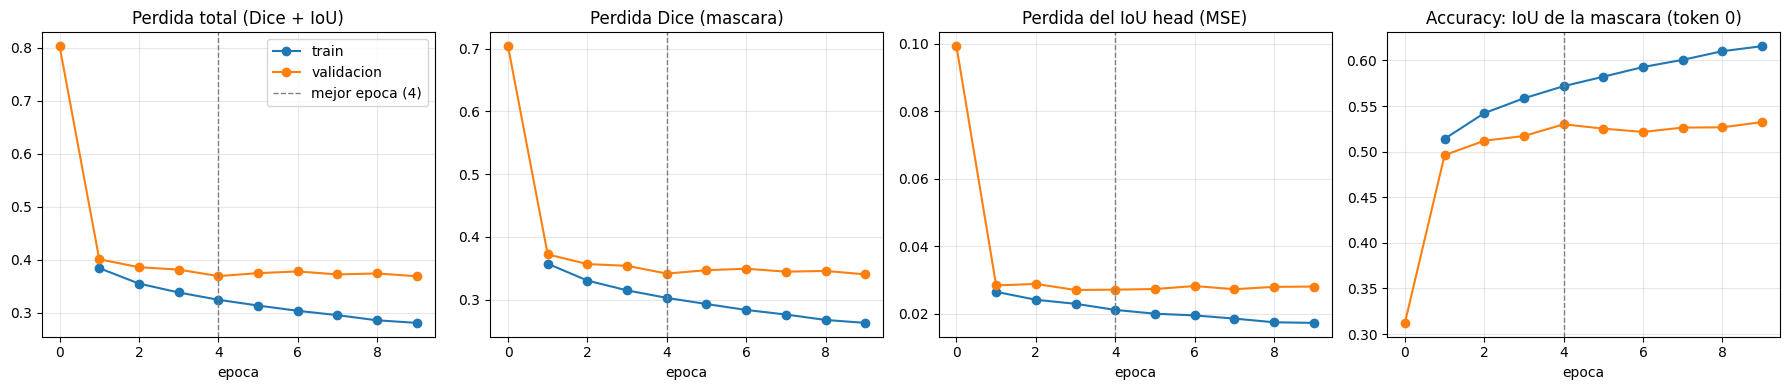

In [22]:
h = pd.DataFrame(history)

panels = [
    ("loss", "Perdida total (Dice + IoU)"),
    ("dice", "Perdida Dice (mascara)"),
    ("iou_loss", "Perdida del IoU head (MSE)"),
    ("mask_iou", "Accuracy: IoU de la mascara (token 0)"),
]

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (key, title) in zip(axes, panels):
    ax.plot(h["epoch"], h[f"train_{key}"], "o-", label="train")
    ax.plot(h["epoch"], h[f"val_{key}"], "o-", label="validacion")
    ax.axvline(best_epoch, color="gray", ls="--", lw=1, label=f"mejor epoca ({best_epoch})")
    ax.set_title(title)
    ax.set_xlabel("epoca")
    ax.grid(True, alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.savefig(DATA_ROOT / "training_curves.png", dpi=150)
plt.show()

## Evaluacion final en TEST

Pesos de la mejor epoca, mismo generador automatico y mismas metricas que la linea base (`baseline_test`). Es la unica vez que el modelo entrenado ve los parches de test.


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


[20/132] 30s
[40/132] 56s
[60/132] 83s
[80/132] 111s
[100/132] 139s
[120/132] 167s
[132/132] 185s

=== Modelo fine-tuned (mejor epoca) - TEST (132 parches) ===
mean_best_iou              0.0639
median_best_iou            0.0006
frac_iou_gt_0.5            0.0585
mask_on_field_fraction     0.5913
n_masks                   41.1212

         mean_best_iou  median_best_iou  frac_iou_gt_0.5  mask_on_field_fraction  n_masks
country                                                                                  
ES              0.0258           0.0000           0.0217                  0.4407  22.0000
FR              0.1020           0.0012           0.0953                  0.7418  60.2424

=== Comparacion en TEST (promedio sobre parches) ===
                        sin entrenar  fine-tuned  diferencia
mean_best_iou                 0.1560      0.0639     -0.0921
median_best_iou               0.0434      0.0006     -0.0428
frac_iou_gt_0.5               0.1423      0.0585     -0.0838
small_mean_

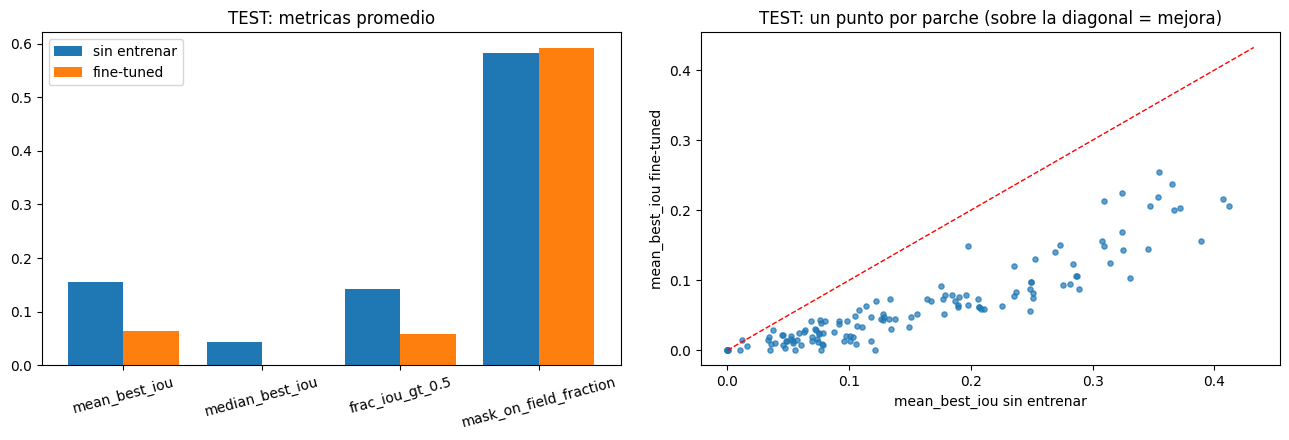

In [23]:
finetuned_test = evaluate_model_on_patches(model, test_patches)
finetuned_test.to_csv(DATA_ROOT / "eval_test_finetuned.csv", index=False)
summarize_eval(finetuned_test, "Modelo fine-tuned (mejor epoca) - TEST")

METRICS = ["mean_best_iou", "median_best_iou", "frac_iou_gt_0.5",
           "small_mean_iou", "large_mean_iou", "mask_on_field_fraction", "n_masks"]


def numeric(df):
    return df[METRICS].apply(pd.to_numeric, errors="coerce")


base_num, fine_num = numeric(baseline_test), numeric(finetuned_test)

comparison = pd.DataFrame({
    "sin entrenar": base_num.mean(),
    "fine-tuned": fine_num.mean(),
})
comparison["diferencia"] = comparison["fine-tuned"] - comparison["sin entrenar"]
print("\n=== Comparacion en TEST (promedio sobre parches) ===")
print(comparison.round(4).to_string())

print("\n=== Por pais ===")
by_country = pd.concat({
    "sin entrenar": base_num.groupby(baseline_test["country"].values).mean(),
    "fine-tuned": fine_num.groupby(finetuned_test["country"].values).mean(),
}, axis=1)
print(by_country[[(g, m) for m in ["mean_best_iou", "frac_iou_gt_0.5"] for g in ["sin entrenar", "fine-tuned"]]]
      .round(4).to_string())

# Comparacion pareada por parche (mismos parches antes y despues) con intervalo bootstrap
a = pd.Series(base_num["mean_best_iou"].values, index=baseline_test["patch"].values)
b = pd.Series(fine_num["mean_best_iou"].values, index=finetuned_test["patch"].values).loc[a.index]
delta = (b - a).values
rng = np.random.RandomState(42)
boot = [rng.choice(delta, size=len(delta), replace=True).mean() for _ in range(5000)]
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"\nDelta mean_best_iou por parche: {delta.mean():+.4f} (IC 95% bootstrap [{lo:+.4f}, {hi:+.4f}]) "
      f"| mejora en {(delta > 0).sum()}/{len(delta)} parches, empeora en {(delta < 0).sum()}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
cols = ["mean_best_iou", "median_best_iou", "frac_iou_gt_0.5", "mask_on_field_fraction"]
x = np.arange(len(cols))
axes[0].bar(x - 0.2, comparison.loc[cols, "sin entrenar"], 0.4, label="sin entrenar")
axes[0].bar(x + 0.2, comparison.loc[cols, "fine-tuned"], 0.4, label="fine-tuned")
axes[0].set_xticks(x)
axes[0].set_xticklabels(cols, rotation=15)
axes[0].set_title("TEST: metricas promedio")
axes[0].legend()
axes[1].scatter(a.values, b.values, s=14, alpha=0.7)
lim = max(a.max(), b.max()) * 1.05
axes[1].plot([0, lim], [0, lim], "r--", lw=1)
axes[1].set_xlabel("mean_best_iou sin entrenar")
axes[1].set_ylabel("mean_best_iou fine-tuned")
axes[1].set_title("TEST: un punto por parche (sobre la diagonal = mejora)")
plt.tight_layout()
plt.savefig(DATA_ROOT / "test_comparison.png", dpi=150)
plt.show()

## Resultados e interpretación

**Entrenamiento** (parches de validación, prompt = centroide de la parcela). El early stopping eligió la época 4. Pérdida Dice 0.70 → 0.34, IoU de la máscara (token 0) 0.31 → 0.53 y error del IoU head (MSE) 0.099 → 0.027. Después de la época 4 la validación se estanca mientras train sigue mejorando (sobreajuste leve).

**Test** (generador automático sin prompts, 132 parches):

| | sin entrenar | fine-tuned |
|---|---|---|
| IoU medio por parcela (best IoU) | 0.156 | **0.064** |
| Parcelas con IoU > 0.5 | 14.2 % | 5.9 % |
| Máscaras por parche | 78.7 | 41.1 |
| Cobertura de la imagen | 0.59 | 0.10 |
| Máscaras sobre parcelas | 0.58 | 0.59 |

**Interpretación.** El fine-tuning mejora lo que se entrenó (prompt en el centro de la parcela), pero **empeora claramente la tarea real sin prompts**: 128 de 132 parches empeoran, en las seis teselas y en ambos países (IC 95 % del cambio por parche: [−0.103, −0.083]). Las máscaras no son peores: **desaparecen** (la mitad de las máscaras y la cobertura cae de 0.59 a 0.10), mientras que las que quedan siguen estando sobre parcelas. Es una pérdida de recall. La validación no pudo advertirlo porque mide el mismo tipo de prompt que se entrena (centroide, token 0), por lo que el early stopping eligió la mejor época para el objetivo equivocado.

**Hipótesis (aún no verificadas)**, por orden de plausibilidad:
1. **El IoU head quedó pesimista.** Solo vio prompts en el centro de parcelas; los puntos de la rejilla sobre bordes, caminos o zonas sin parcela reciben un IoU predicho bajo y el filtro `pred_iou_thresh=0.5` los descarta.
2. **Los tokens 1–3 empeoraron.** El generador usa los tokens 1–3, pero solo se entrenó el token 0; cambiar la capa compartida (`layers[1]`) puede haberlos degradado.
3. **Cambió el `stability_score`**, y el filtro `stability_score_thresh=0.8` elimina más máscaras.

**Cómo distinguirlas:** repetir la evaluación en test con los filtros desactivados (`pred_iou_thresh=0`, `stability_score_thresh=0`) y comparar la distribución del IoU predicho y de la estabilidad. Si el modelo recupera rendimiento, el problema es el IoU head o los filtros (1, 3); si no, las máscaras en sí empeoraron (2).

**Limitaciones.** Una sola ejecución y una semilla, sin ajuste de hiperparámetros. Entrenamiento con prompts tomados del ground truth, evaluación con una rejilla de puntos: el desajuste entre ambos es la causa más probable del resultado.
